In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
df = pd.read_csv(r"C:\Users\bkapa\Downloads\Fraud Detection Dataset.csv")
print(df.shape)
df.head()

(51000, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [5]:
df.columns.tolist()
list(df)

['Transaction_ID',
 'User_ID',
 'Transaction_Amount',
 'Transaction_Type',
 'Time_of_Transaction',
 'Device_Used',
 'Location',
 'Previous_Fraudulent_Transactions',
 'Account_Age',
 'Number_of_Transactions_Last_24H',
 'Payment_Method',
 'Fraudulent']

In [6]:
df=df.dropna()

In [7]:
missing_percent = df.isnull().mean()*100

print(missing_percent)

Transaction_ID                      0.0
User_ID                             0.0
Transaction_Amount                  0.0
Transaction_Type                    0.0
Time_of_Transaction                 0.0
Device_Used                         0.0
Location                            0.0
Previous_Fraudulent_Transactions    0.0
Account_Age                         0.0
Number_of_Transactions_Last_24H     0.0
Payment_Method                      0.0
Fraudulent                          0.0
dtype: float64


In [8]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 688


# Task 1: Column wise Duplicate count

In [9]:
for col in df.columns:
    print(col, ":", df[col].duplicated().sum())

Transaction_ID : 787
User_ID : 35583
Transaction_Amount : 2667
Transaction_Type : 39578
Time_of_Transaction : 39559
Device_Used : 39579
Location : 39575
Previous_Fraudulent_Transactions : 39578
Account_Age : 39464
Number_of_Transactions_Last_24H : 39569
Payment_Method : 39578
Fraudulent : 39581


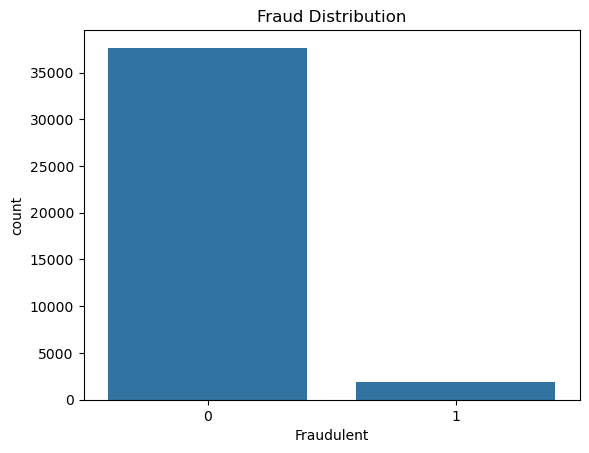

In [10]:
sns.countplot(x="Fraudulent", data=df)

plt.title("Fraud Distribution")

plt.show()

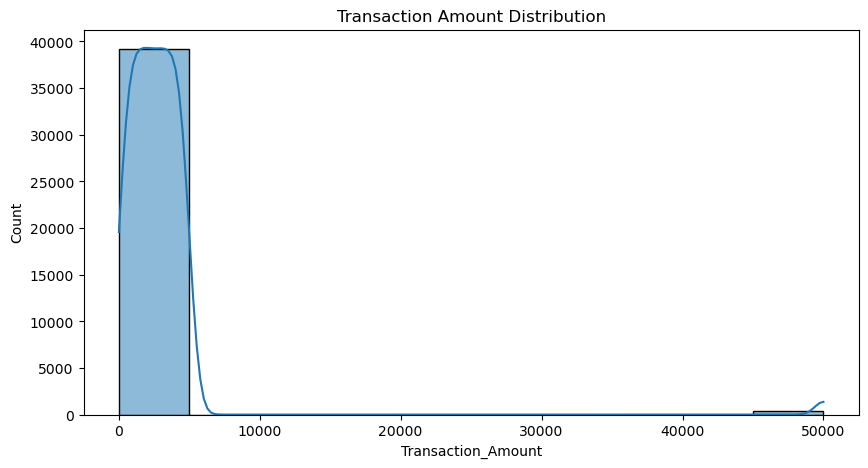

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Transaction_Amount"],
    bins=10,
    kde=True
)

plt.title("Transaction Amount Distribution")

plt.show()

# Task 2: Cluster for Payment_Method v/s Fraudulent

Fraudulent         0    1
Payment_Method           
Credit Card     9009  460
Debit Card      9167  456
Invalid Method  1174   56
Net Banking     9029  474
UPI             9272  486
Fraudulent              0         1
Payment_Method                     
Credit Card     95.142042  4.857958
Debit Card      95.261353  4.738647
Invalid Method  95.447154  4.552846
Net Banking     95.012101  4.987899
UPI             95.019471  4.980529


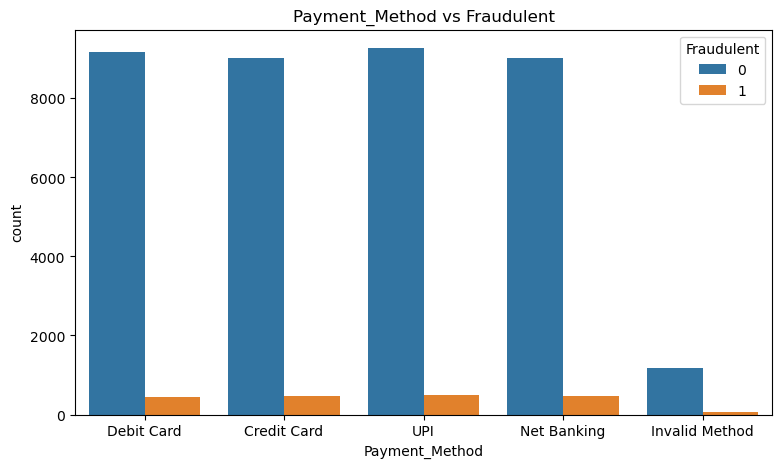

In [12]:
print(pd.crosstab(df["Payment_Method"], df["Fraudulent"]))
print(pd.crosstab(df["Payment_Method"], df["Fraudulent"], normalize="index")*100)

plt.figure(figsize=(9,5))
sns.countplot(x="Payment_Method", hue="Fraudulent", data=df)
plt.title("Payment_Method vs Fraudulent")
plt.show()

<Axes: >

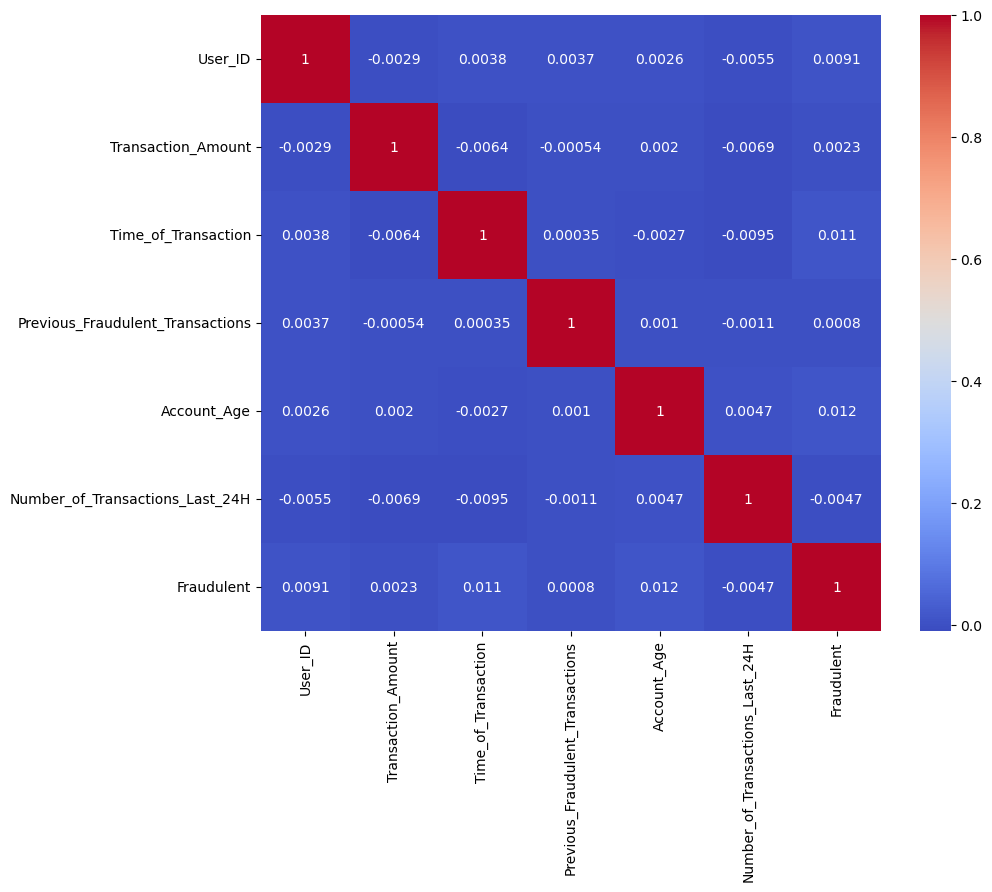

In [13]:
numeric = df.select_dtypes(include="number")

plt.figure(figsize=(10,8))

sns.heatmap(

numeric.corr(),

annot=True,

cmap="coolwarm"

)

# Outlier 

Text(0.5, 1.0, 'Transaction Amount Boxplot')

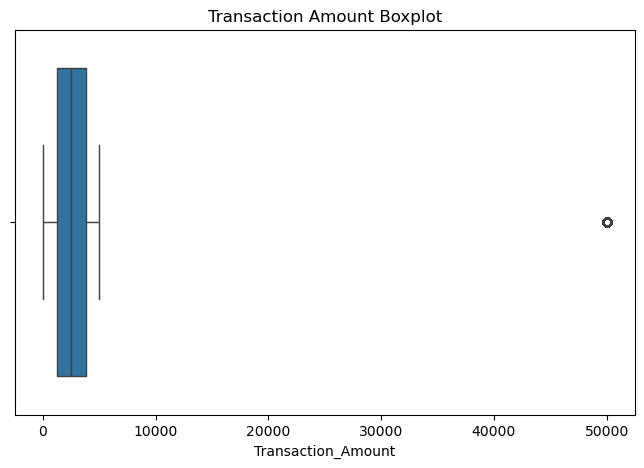

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Transaction_Amount"]
)

plt.title("Transaction Amount Boxplot")

In [15]:
Q1 = df["Transaction_Amount"].quantile(0.25)

Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR

upper = Q3 + 1.5*IQR


outliers = df[
    (df["Transaction_Amount"] < lower) |
    (df["Transaction_Amount"] > upper)
]

#Lower_outlier= df[df["Transaction_Amount"] < lower]

#Lower_outlier.head()

#upper_outlier= df[df["Transaction_Amount"] < upper]

#upper_outlier.head()
#upper_outlier.shape
#Lower_outlier.shape
print(outliers.shape)
#outliers.head()

(416, 12)


# Task 3: Find Outliers from: Time_of_Transaction, and create graph

Bounds: -13.0 35.0
Outliers: 0


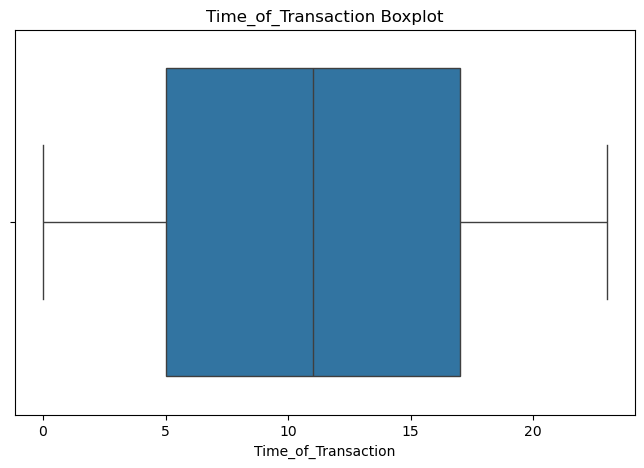

In [16]:
Q1 = df["Time_of_Transaction"].quantile(0.25)
Q3 = df["Time_of_Transaction"].quantile(0.75)
IQR = Q3 - Q1
lower_t = Q1 - 1.5*IQR
upper_t = Q3 + 1.5*IQR

time_outliers = df[(df["Time_of_Transaction"] < lower_t) | (df["Time_of_Transaction"] > upper_t)]
print("Bounds:", lower_t, upper_t)
print("Outliers:", time_outliers.shape[0])

plt.figure(figsize=(8,5))
sns.boxplot(x=df["Time_of_Transaction"])
plt.title("Time_of_Transaction Boxplot")
plt.show()

# Task 4: Identify Uncommon/Common Value/s

In [17]:
cat_cols = ["Transaction_Type", "Device_Used", "Location", "Payment_Method", "Previous_Fraudulent_Transactions", "Number_of_Transactions_Last_24H", "Time_of_Transaction"]

for col in cat_cols:
    vc = df[col].value_counts()
    print(col, "| most common:", vc.index[0], vc.iloc[0], "| least common:", vc.index[-1], vc.iloc[-1])

# values that make up less than 5% of a column (uncommon)
for col in ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]:
    share = df[col].value_counts(normalize=True)*100
    print(col, "uncommon:", share[share < 5].round(2).to_dict())

Transaction_Type | most common: Bank Transfer 8012 | least common: Online Purchase 7847
Device_Used | most common: Desktop 12835 | least common: Unknown Device 1237
Location | most common: Boston 5045 | least common: Houston 4877
Payment_Method | most common: UPI 9758 | least common: Invalid Method 1230
Previous_Fraudulent_Transactions | most common: 2 8083 | least common: 3 7798
Number_of_Transactions_Last_24H | most common: 5 2934 | least common: 9 2693
Time_of_Transaction | most common: 18.0 1737 | least common: 19.0 1571
Transaction_Type uncommon: {}
Device_Used uncommon: {'Unknown Device': 3.13}
Location uncommon: {}
Payment_Method uncommon: {'Invalid Method': 3.11}


In [18]:
features = [
    "Transaction_Amount",
    "Previous_Fraudulent_Transactions",
    "Account_Age",
    "Number_of_Transactions_Last_24H"
]


In [19]:
from sklearn.preprocessing import StandardScaler

X = df[features]
#X=X.dropna()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [20]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=15
)

labels = dbscan.fit_predict(X_scaled)

In [21]:
df["Cluster"] = labels
#df.head()
df["Cluster"].value_counts()

Cluster
 0    39167
 1      408
-1        8
Name: count, dtype: int64

# Task 5: Identify Anomalies with -1 (for different feature set)

In [23]:
# Different feature set
features2 = ["Transaction_Amount", "Time_of_Transaction", "Account_Age", "Number_of_Transactions_Last_24H"]

X2_scaled = StandardScaler().fit_transform(df[features2])
df["Cluster2"] = DBSCAN(eps=0.8, min_samples=100).fit_predict(X2_scaled)

print(df["Cluster2"].value_counts())
suspicious2 = df[df["Cluster2"] == -1]
print(suspicious2.head())

Cluster2
 0    39167
-1      416
Name: count, dtype: int64
    Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
166           T167     1502             49997.8      POS Payment   
245           T246     2306             49997.8     Bill Payment   
298           T299     2153             49997.8  Online Purchase   
317           T318     4681             49997.8     Bill Payment   
421           T422     4987             49997.8  Online Purchase   

     Time_of_Transaction Device_Used       Location  \
166                  3.0     Desktop          Miami   
245                  1.0     Desktop       New York   
298                 18.0      Tablet  San Francisco   
317                  0.0      Mobile        Houston   
421                  0.0     Desktop    Los Angeles   

     Previous_Fraudulent_Transactions  Account_Age  \
166                                 3          108   
245                                 3           78   
298                                 2  

In [24]:
suspicious = df[df["Cluster"] == -1]

print(suspicious.head())

      Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
317             T318     4681             49997.8     Bill Payment   
8146           T8147     1640             49997.8     Bill Payment   
15441         T15442     4030             49997.8    Bank Transfer   
19824         T19825     2206             49997.8  Online Purchase   
22058         T22059     3612             49997.8    Bank Transfer   

       Time_of_Transaction Device_Used     Location  \
317                    0.0      Mobile      Houston   
8146                  17.0      Tablet  Los Angeles   
15441                 20.0     Desktop      Seattle   
19824                 14.0      Mobile        Miami   
22058                 20.0      Tablet     New York   

       Previous_Fraudulent_Transactions  Account_Age  \
317                                   4            4   
8146                                  4            7   
15441                                 0            5   
19824                   

# Task 6: Create Graphs for Anomalies

### Cluster Graph (any two attributes)

In [25]:
x_attr = "Transaction_Amount"   
y_attr = "Previous_Fraudulent_Transactions"          


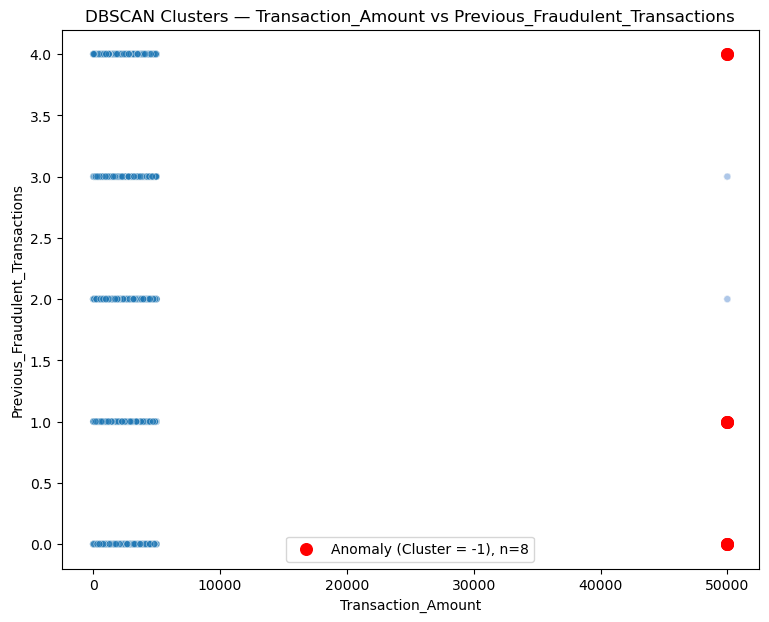

In [26]:
non_noise = df[df["Cluster"] != -1]
noise = df[df["Cluster"] == -1]

sample_size = min(3000, len(non_noise))
plot_sample = non_noise.sample(n=sample_size, random_state=42)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_sample,
    x=x_attr, y=y_attr,
    hue="Cluster",
    palette="tab20",
    alpha=0.6, s=25,
    legend=False
)

plt.scatter(
    noise[x_attr], noise[y_attr],
    c="red", marker="o", s=70,
    label=f"Anomaly (Cluster = -1), n={len(noise)}"
)

plt.xlabel(x_attr)
plt.ylabel(y_attr)
plt.title(f"DBSCAN Clusters — {x_attr} vs {y_attr}")
plt.legend()
plt.show()


### Anomaly graph (feature set: 2)

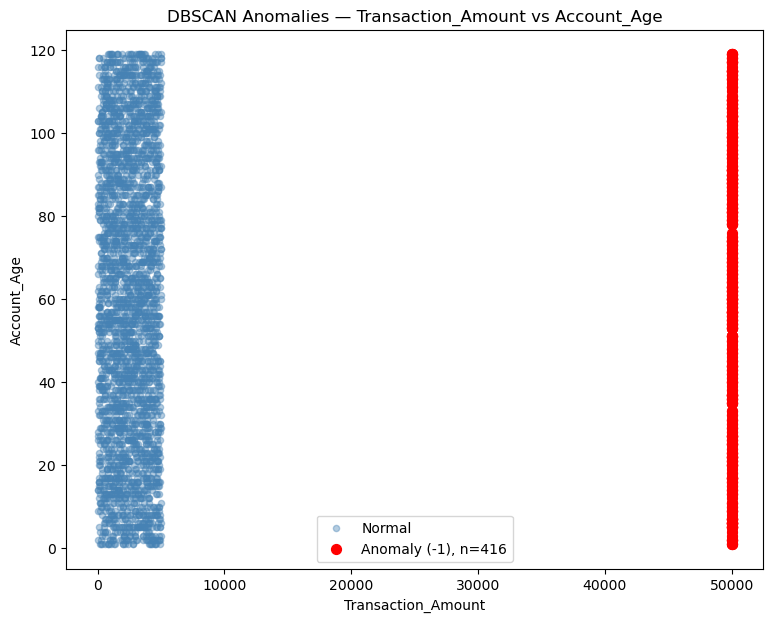

In [27]:
non_noise2 = df[df["Cluster2"] != -1].sample(n=3000, random_state=42)
noise2 = df[df["Cluster2"] == -1]

plt.figure(figsize=(9,7))
plt.scatter(non_noise2["Transaction_Amount"], non_noise2["Account_Age"], c="steelblue", alpha=0.4, s=20, label="Normal")
plt.scatter(noise2["Transaction_Amount"], noise2["Account_Age"], c="red", s=50, label=f"Anomaly (-1), n={len(noise2)}")
plt.xlabel("Transaction_Amount")
plt.ylabel("Account_Age")
plt.title("DBSCAN Anomalies — Transaction_Amount vs Account_Age")
plt.legend()
plt.show()

             Set 1     Set 2
Normal    4.876816  4.871448
Anomaly  25.000000  5.769231


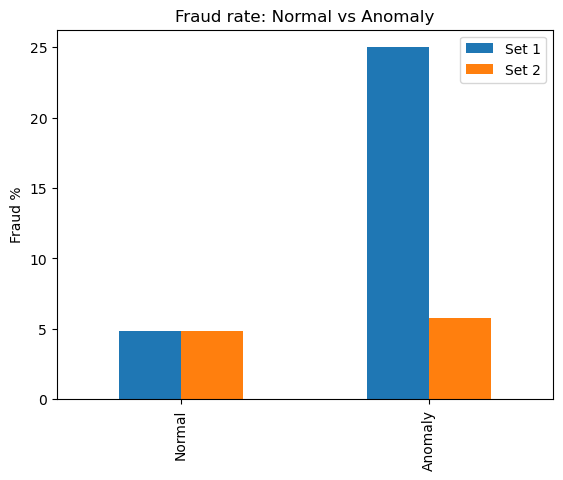

In [28]:
# anomalies vs normal: fraud rate
rates = pd.DataFrame({
    "Set 1": df.groupby(df["Cluster"] == -1)["Fraudulent"].mean()*100,
    "Set 2": df.groupby(df["Cluster2"] == -1)["Fraudulent"].mean()*100
})
rates.index = ["Normal", "Anomaly"]
print(rates)
rates.plot(kind="bar")
plt.ylabel("Fraud %")
plt.title("Fraud rate: Normal vs Anomaly")
plt.show()

**Observations**
- Column-wise duplicates: only Transaction_ID (787) and the amount column (2,667) are meaningfully duplicated; other columns repeat because they have few distinct values.
- Payment_Method vs Fraudulent: fraud rate is ~4.5-5% for every method, so payment method does not separate fraud.
- Time_of_Transaction has no IQR outliers (values are hours 0-23, bounds -13 to 35).
- Uncommon values: Unknown Device (3.1%) and Invalid Method (3.1%). Most common: Desktop and UPI.
- Anomalies (-1): set 1 flags only 8 rows and set 2 flags 416 rows, all with the maximum amount (49997.8). Set 1's 25% fraud rate rests on just 8 rows; set 2's 416 rows are 5.8%, close to normal (4.9%), so extreme amount alone is not a strong fraud signal.
